In [1]:
from pathlib import Path
import sys
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Works when the notebook starts in the repository root or notebooks folder.
ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent

assert (ROOT / "src").is_dir(), "Open the notebook from this repository."

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.data_preparation import OCTMNISTDataPreprocessor

RESULTS = ROOT / "results" / "mobilenet_v1"
RESULTS.mkdir(parents=True, exist_ok=True)

tf.keras.utils.set_random_seed(42)

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))
print("Repository:", ROOT)

Matplotlib is building the font cache; this may take a moment.


TensorFlow: 2.21.0
GPUs: []
Repository: F:\PR\CNN-Edge-Image-Classifier


In [2]:
data_path = ROOT / "data" / "octmnist_64.npz"
assert data_path.exists(), f"Dataset not found: {data_path}"

preprocessor = OCTMNISTDataPreprocessor(data_path=data_path)

X_train, X_val, X_test, y_train, y_val, y_test = (
    preprocessor.load_dataset()
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)
print("Pixel range:", X_train.min(), X_train.max())

assert X_train.shape[1:] == (64, 64, 1)
assert set(np.unique(y_train)) == {0, 1, 2, 3}

Loading OCTMNIST data...
Original splits loaded: Training Datapoints: 97477, Validation Datapoints: 10832, Test Datapoints: 1000
Total Data Points: 109309
Creating new stratified splits...
New splits created: Training Datapoints: 76516, Validation Datapoints: 16396, Test Datapoints: 16397
Shapes of returned Splits: X_train: (76516, 64, 64, 1), X_val: (16396, 64, 64, 1), X_test: (16397, 64, 64, 1)
Shapes of returned Labels: y_train: (76516,), y_val: (16396,), y_test: (16397,)
Training: (76516, 64, 64, 1) (76516,)
Validation: (16396, 64, 64, 1) (16396,)
Testing: (16397, 64, 64, 1) (16397,)
Pixel range: 0 255


In [3]:
base_model = tf.keras.applications.MobileNet(
    input_shape=(64, 64, 3),
    alpha=1.0,
    include_top=False,
    weights="imagenet",
)

# Stage 1: freeze the pretrained backbone.
base_model.trainable = False

inputs = tf.keras.Input(shape=(64, 64, 1), name="grayscale_image")

# Repeat the grayscale channel to obtain three channels.
x = tf.keras.layers.Concatenate(axis=-1)([inputs, inputs, inputs])

# Equivalent to MobileNetV1 preprocess_input for raw 0–255 pixels.
x = tf.keras.layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1,
    name="mobilenet_preprocessing",
)(x)

x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(4, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs, name="MobileNetV1_OCTMNIST")
model.summary()

C:\Users\REDTECH\AppData\Local\Temp\ipykernel_3088\1121329935.py:1: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNet(


17225924/17225924 ━━━━━━━━━━━━━━━━━━━━ 57s 3us/step


Model: "MobileNetV1_OCTMNIST"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ grayscale_image     │ (None, 64, 64, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 64, 3) │          0 │ grayscale_image[… │
│ (Concatenate)       │                   │            │ grayscale_image[… │
│                     │                   │            │ grayscale_image[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenet_preproce… │ (None, 64, 64, 3) │          0 │ concatenate[0][0] │
│ (Rescaling)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenet_1.00_224  │ (None, 2, 2,      │  3,228,864 │ mobilenet_prepro… │
│ (Functional)        │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1024)      │          0 │ mobilenet_1.00_2… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 1024)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 4)         │      4,100 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,232,964 (12.33 MB)

 Trainable params: 4,100 (16.02 KB)

 Non-trainable params: 3,228,864 (12.32 MB)

In [4]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

head_checkpoint = RESULTS / "head_best.weights.h5"

history_head = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=32,
    shuffle=True,
    callbacks=[
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(head_checkpoint),
            monitor="val_loss",
            save_best_only=True,
            save_weights_only=True,
        ),
        tf.keras.callbacks.CSVLogger(str(RESULTS / "head_training.csv")),
    ],
)

model.load_weights(str(head_checkpoint))

Epoch 1/5
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 262s 103ms/step - accuracy: 0.7784 - loss: 0.6493 - val_accuracy: 0.8097 - val_loss: 0.5505
Epoch 2/5
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 248s 104ms/step - accuracy: 0.7988 - loss: 0.5888 - val_accuracy: 0.8121 - val_loss: 0.5485
Epoch 3/5
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 248s 104ms/step - accuracy: 0.7991 - loss: 0.5861 - val_accuracy: 0.8134 - val_loss: 0.5471
Epoch 4/5
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 248s 104ms/step - accuracy: 0.8006 - loss: 0.5845 - val_accuracy: 0.8151 - val_loss: 0.5405
Epoch 5/5
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 266s 111ms/step - accuracy: 0.8000 - loss: 0.5838 - val_accuracy: 0.8134 - val_loss: 0.5434


In [5]:
base_model.trainable = True

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile after changing which weights are trainable.
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

fine_checkpoint = RESULTS / "finetuned_best.weights.h5"

history_fine = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    shuffle=True,
    callbacks=[
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(fine_checkpoint),
            monitor="val_loss",
            save_best_only=True,
            save_weights_only=True,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-7,
        ),
        tf.keras.callbacks.CSVLogger(str(RESULTS / "finetuning.csv")),
    ],
)

# Select the best fine-tuned epoch using validation loss.
model.load_weights(str(fine_checkpoint))

Epoch 1/20
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 539s 215ms/step - accuracy: 0.8699 - loss: 0.3885 - val_accuracy: 0.9031 - val_loss: 0.2845 - learning_rate: 1.0000e-05
Epoch 2/20
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 637s 266ms/step - accuracy: 0.9101 - loss: 0.2690 - val_accuracy: 0.9142 - val_loss: 0.2523 - learning_rate: 1.0000e-05
Epoch 3/20
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 638s 267ms/step - accuracy: 0.9216 - loss: 0.2305 - val_accuracy: 0.9227 - val_loss: 0.2275 - learning_rate: 1.0000e-05
Epoch 4/20
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 618s 258ms/step - accuracy: 0.9313 - loss: 0.2047 - val_accuracy: 0.9296 - val_loss: 0.2093 - learning_rate: 1.0000e-05
Epoch 5/20
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 582s 243ms/step - accuracy: 0.9368 - loss: 0.1867 - val_accuracy: 0.9333 - val_loss: 0.1975 - learning_rate: 1.0000e-05
Epoch 6/20
2392/2392 ━━━━━━━━━━━━━━━━━━━━ 593s 248ms/step - accuracy: 0.9414 - loss: 0.1717 - val_accuracy: 0.9396 - val_loss: 0.1858 - learning_rate: 1.0000e-05
Epoch 7/20
2392/2392 ━━━━━━━

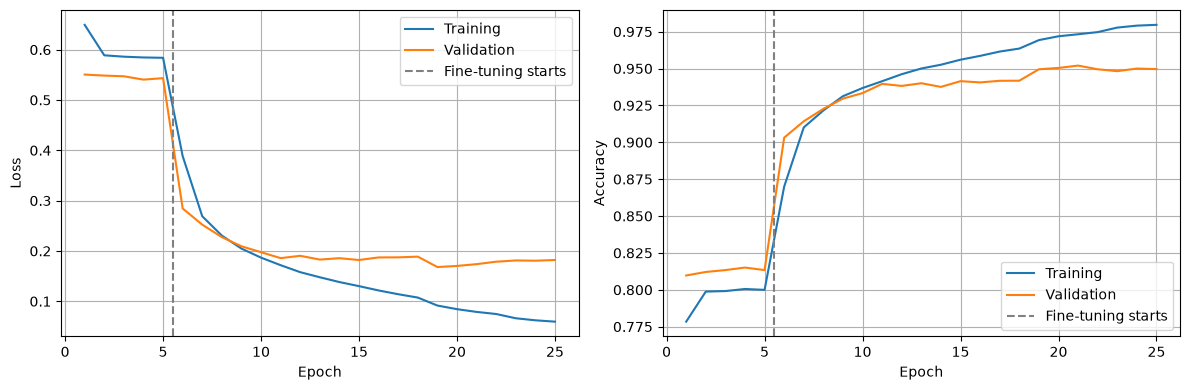

In [6]:
history = {
    key: history_head.history[key] + history_fine.history[key]
    for key in ["loss", "val_loss", "accuracy", "val_accuracy"]
}

epochs = np.arange(1, len(history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(epochs, history[metric], label="Training")
    ax.plot(epochs, history[f"val_{metric}"], label="Validation")
    ax.axvline(
        len(history_head.history["loss"]) + 0.5,
        color="gray",
        linestyle="--",
        label="Fine-tuning starts",
    )
    ax.set_xlabel("Epoch")
    ax.set_ylabel(metric.capitalize())
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.savefig(RESULTS / "training_curves.png", dpi=200)
plt.show()

513/513 ━━━━━━━━━━━━━━━━━━━━ 41s 73ms/step
Test accuracy: 0.9507
              precision    recall  f1-score   support

         CNV       0.97      0.96      0.97      5619
         DME       0.96      0.93      0.95      1739
      Drusen       0.77      0.75      0.76      1330
      Normal       0.96      0.98      0.97      7709

    accuracy                           0.95     16397
   macro avg       0.92      0.91      0.91     16397
weighted avg       0.95      0.95      0.95     16397



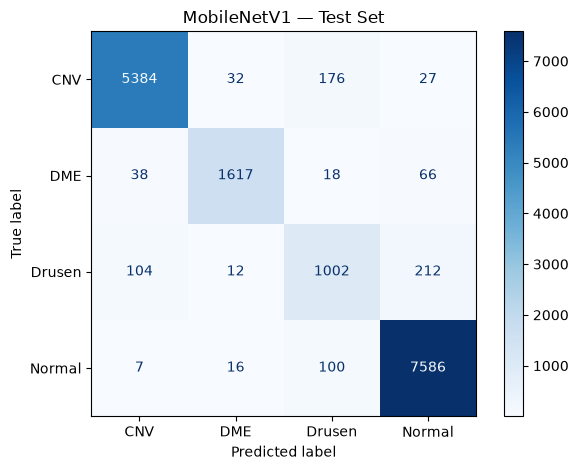

In [7]:
class_names = ["CNV", "DME", "Drusen", "Normal"]

probabilities = model.predict(X_test, batch_size=32)
predictions = np.argmax(probabilities, axis=1)
y_true = np.asarray(y_test).reshape(-1)

test_accuracy = accuracy_score(y_true, predictions)

report = classification_report(
    y_true,
    predictions,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)

print(f"Test accuracy: {test_accuracy:.4f}")
print(classification_report(
    y_true,
    predictions,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    zero_division=0,
))

pd.DataFrame(report).T.to_csv(RESULTS / "classification_report.csv")

cm = confusion_matrix(y_true, predictions, labels=[0, 1, 2, 3])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names,
).plot(cmap="Blues")

plt.title("MobileNetV1 — Test Set")
plt.tight_layout()
plt.savefig(RESULTS / "confusion_matrix.png", dpi=200)
plt.show()

np.save(RESULTS / "confusion_matrix.npy", cm)

In [8]:
total_params = model.count_params()
trainable_params = sum(
    int(np.prod(weight.shape)) for weight in model.trainable_weights
)

inference_model = tf.keras.models.clone_model(model)
inference_model.set_weights(model.get_weights())

model_path = RESULTS / "mobilenet_v1_inference.keras"
inference_model.save(str(model_path))

# Decimal MB: 1 MB = 1,000,000 bytes.
file_size_mb = model_path.stat().st_size / 1_000_000
estimated_fp32_mb = total_params * 4 / 1_000_000

metrics = {
    "model": "MobileNetV1",
    "input_shape": [64, 64, 1],
    "total_parameters": int(total_params),
    "trainable_parameters": int(trainable_params),
    "estimated_fp32_parameter_MB": float(estimated_fp32_mb),
    "saved_keras_model_MB": float(file_size_mb),
    "test_accuracy": float(test_accuracy),
    "macro_precision": float(report["macro avg"]["precision"]),
    "macro_recall": float(report["macro avg"]["recall"]),
    "macro_f1": float(report["macro avg"]["f1-score"]),
}

print(json.dumps(metrics, indent=2))

with open(RESULTS / "metrics.json", "w") as file:
    json.dump(metrics, file, indent=2)

{
  "model": "MobileNetV1",
  "input_shape": [
    64,
    64,
    1
  ],
  "total_parameters": 3232964,
  "trainable_parameters": 3189188,
  "estimated_fp32_parameter_MB": 12.931856,
  "saved_keras_model_MB": 38.798033,
  "test_accuracy": 0.9507226931755809,
  "macro_precision": 0.9179472528263184,
  "macro_recall": 0.9063626079610987,
  "macro_f1": 0.9119974951942373
}
